In [1]:
import torch
import matplotlib.pyplot as plt

In [2]:
torch.manual_seed(42)
x = torch.tensor([[0.0],
                  [0.0],
                  [0.0],
                  [7.0],
                  [0.0],
                  [0.0],
                  [0.0]])
y = torch.tensor([[7.0]])

input_size = 1
hidden_size = 4
output_size = 1

# Weights
Wx = torch.randn(hidden_size, input_size, requires_grad=True)
Wh = torch.randn(hidden_size, hidden_size, requires_grad=True)
b = torch.zeros(hidden_size, requires_grad=True)
Wy = torch.randn(output_size, hidden_size, requires_grad=True)
by = torch.zeros(output_size, requires_grad=True)

In [3]:
def forward_4d(x):
    h = torch.zeros(hidden_size)
    states = []

    for t in range(len(x)):
        h = torch.tanh(Wx @ x[t] + Wh @ h + b)
        states.append(h)

    y_hat = Wy @ h + by

    return y_hat, states

In [4]:
lr = 0.05

for epoch in range(2000):
    y_hat, states = forward_4d(x)
    loss = ((y_hat - y) ** 2).mean()
    loss.backward()

    with torch.no_grad():
        Wx -= lr * Wx.grad
        Wh -= lr * Wh.grad
        b -= lr * b.grad
        Wy -= lr * Wy.grad
        by -= lr * by.grad

    Wx.grad.zero_()
    Wh.grad.zero_()
    b.grad.zero_()
    Wy.grad.zero_()
    by.grad.zero_()

    if epoch % 200 == 0:
        print(f"Epoch {epoch:4d} | "
            f"Loss = {loss.item():.6f} | "
            f"Prediction = {y_hat.item():.6f}")

Epoch    0 | Loss = 16.262589 | Prediction = 2.967310
Epoch  200 | Loss = 0.000000 | Prediction = 7.000000
Epoch  400 | Loss = 0.000000 | Prediction = 7.000000
Epoch  600 | Loss = 0.000000 | Prediction = 7.000000
Epoch  800 | Loss = 0.000000 | Prediction = 7.000000
Epoch 1000 | Loss = 0.000000 | Prediction = 7.000000
Epoch 1200 | Loss = 0.000000 | Prediction = 7.000000
Epoch 1400 | Loss = 0.000000 | Prediction = 7.000000
Epoch 1600 | Loss = 0.000000 | Prediction = 7.000000
Epoch 1800 | Loss = 0.000000 | Prediction = 7.000000


In [7]:
y_hat, states = forward_4d(x)
print("\nPredizione finale:", y_hat.item())
print("\nStati:")
for t, h in enumerate(states):
    print(f"h[{t}] =", h.detach().numpy())


Predizione finale: 7.0

Stati:
h[0] = [ 1.         -0.9904037  -0.9999899  -0.02695302]
h[1] = [ 1.         -0.99999934 -1.          0.637406  ]
h[2] = [ 1.        -0.9999626 -1.        -0.7851031]
h[3] = [ 1.         -1.         -1.         -0.99995184]
h[4] = [ 1.         -1.         -0.9999998   0.99782383]
h[5] = [ 1.         -0.99966025 -1.         -0.9669042 ]
h[6] = [ 1.         -1.         -0.9999998   0.99739385]


In [6]:
y_hat, states = forward_4d(x)
loss = ((y_hat - y) ** 2).mean()
gradients = torch.autograd.grad(loss, states, retain_graph=True)

for t, g in enumerate(gradients):
    print(f"h[{t}] -> {g.detach().numpy()}")

h[0] -> [0. 0. 0. 0.]
h[1] -> [0. 0. 0. 0.]
h[2] -> [0. 0. 0. 0.]
h[3] -> [0. 0. 0. 0.]
h[4] -> [0. 0. 0. 0.]
h[5] -> [0. 0. 0. 0.]
h[6] -> [0. 0. 0. 0.]


In [5]:
y_hat, states = forward_4d(x)

loss = ((y_hat - y) ** 2).mean()

print("Predizione:", y_hat.item())
print("Target:", y.item())
print("Errore:", (y_hat - y).item())
print("Loss:", loss.item())

Predizione: 7.0
Target: 7.0
Errore: 0.0
Loss: 0.0


In [14]:
# Misuriamo DIRETTAMENTE la sensibilità della predizione, visto che la loss è circa 0...
y_hat, states = forward_4d(x)

dy_dh = torch.autograd.grad(y_hat, states, retain_graph=True)

for t, g in enumerate(dy_dh):
    print(f"h[{t}] -> dy/dh =", g.detach().numpy())

h[0] -> dy/dh = [-8.9416901e-09  6.1128402e-10 -6.2321961e-09  1.2796283e-08]
h[1] -> dy/dh = [ 5.5171054e-09 -3.7714604e-10  3.8454031e-09 -7.8954354e-09]
h[2] -> dy/dh = [-5.2685620e-09  3.6017689e-10 -3.6720917e-09  7.5397395e-09]
h[3] -> dy/dh = [ 2.0038566e-05 -1.3695853e-06  1.3965113e-05 -2.8675044e-05]
h[4] -> dy/dh = [-0.00168824  0.00011505 -0.001178    0.00241618]
h[5] -> dy/dh = [ 0.00950836 -0.00064955  0.00662508 -0.01360462]
h[6] -> dy/dh = [ 1.7472475 -1.7870129 -1.7398024  0.9574549]


In [6]:
# Supponiamo che il risultato corretto fosse 8 invece di 7
y_hat, states = forward_4d(x)
y_analysis = torch.tensor([8.0])
loss_analysis = ((y_hat - y_analysis) ** 2).mean()

dL_dh = torch.autograd.grad(loss_analysis, states, retain_graph=True)

for t, g in enumerate(dL_dh):
    print(f"h[{t}] -> dL/dh =", g.detach().numpy())

h[0] -> dL/dh = [ 1.7883380e-08 -1.2225680e-09  1.2464392e-08 -2.5592566e-08]
h[1] -> dL/dh = [-1.1034211e-08  7.5429207e-10 -7.6908062e-09  1.5790871e-08]
h[2] -> dL/dh = [ 1.0537124e-08 -7.2035378e-10  7.3441835e-09 -1.5079479e-08]
h[3] -> dL/dh = [-4.0077131e-05  2.7391707e-06 -2.7930226e-05  5.7350087e-05]
h[4] -> dL/dh = [ 0.00337648 -0.0002301   0.002356   -0.00483237]
h[5] -> dL/dh = [-0.01901671  0.0012991  -0.01325016  0.02720923]
h[6] -> dL/dh = [-3.494495   3.5740259  3.4796047 -1.9149098]


In [7]:
attribution = torch.stack([g.abs() for g in dy_dh])
print("Shape:", attribution.shape)
print(attribution.detach().numpy())

time_attribution = attribution.sum(dim=1)
print("Attribution per timestep:")

for t, value in enumerate(time_attribution):
    print(f"t={t}: {value.item():.8f}")

NameError: name 'dy_dh' is not defined

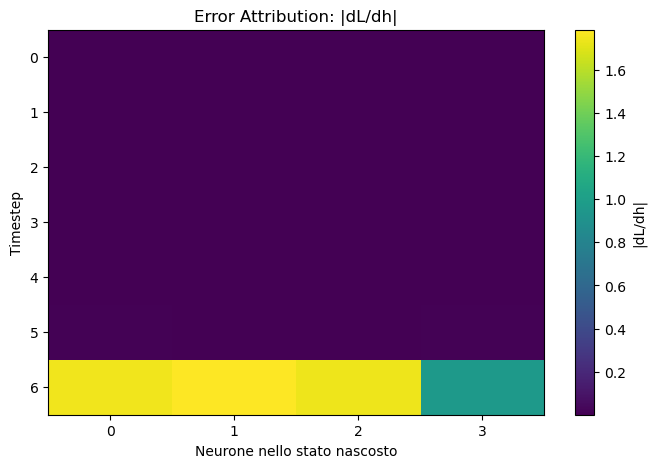

In [17]:
# Creazione della heatmap
plt.figure(figsize=(8,5))

plt.imshow(attribution.detach().numpy(), aspect="auto")
plt.xlabel("Neurone nello stato nascosto")
plt.ylabel("Timestep")
plt.title("Error Attribution: |dL/dh|")

plt.colorbar(label="|dL/dh|")

plt.xticks(range(4))
plt.yticks(range(7))

plt.show()

In [ ]:
# A = -2J
J = torch.stack(dy_dh)

print("Shape:", J.shape)
print(J.detach().numpy())

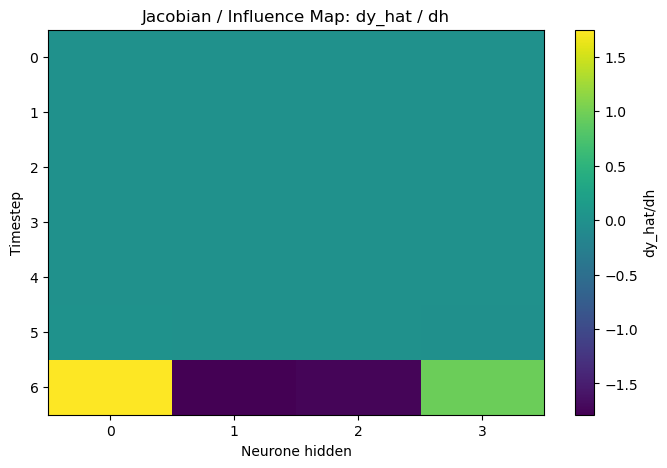

In [20]:
# Heatmap (nuova)
plt.figure(figsize=(8, 5))
plt.imshow(J.detach().numpy(), aspect="auto")

plt.xlabel("Neurone hidden")
plt.ylabel("Timestep")
plt.title("Jacobian / Influence Map: dy_hat / dh")

plt.colorbar(label="dy_hat/dh")

plt.xticks(range(4))
plt.yticks(range(7))

plt.show()

In [ ]:
# Versione assoluta della heatmap
J_abs = J.abs()

plt.figure(figsize=(8, 5))

plt.imshow(J_abs.detach().numpy(), aspect="auto")

plt.xlabel("Neurone hidden")
plt.ylabel("Timestep")
plt.title("Influence Magnitude: |dy_hat/dh|")

plt.colorbar(label="|dy_hat/dh|")

plt.xticks(range(4))
plt.yticks(range(7))

plt.show()

In [23]:
y_hat, states = forward_4d(x)

h6 = states[6]

# usiamo ancora il target artificiale 8
y_analysis = torch.tensor([8.0])

def loss_from_h6(h):
    y_local = Wy @ h + by
    return ((y_local - y_analysis) ** 2).mean()

H6 = torch.autograd.functional.hessian(loss_from_h6, h6)

print(H6.detach().numpy())

[[ 6.105747  -6.2447076 -6.0797305  3.3458214]
 [-6.2447076  6.3868303  6.2180986 -3.4219687]
 [-6.0797305  6.2180986  6.0538244 -3.3315647]
 [ 3.3458214 -3.4219687 -3.3315647  1.8334398]]


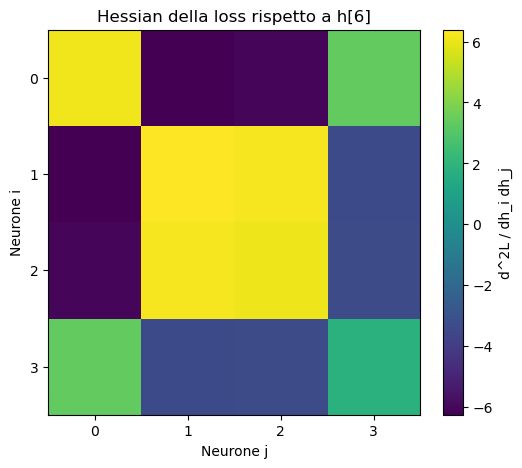

In [24]:
plt.figure(figsize=(6, 5))

plt.imshow(H6.detach().numpy(), aspect="auto")

plt.xlabel("Neurone j")
plt.ylabel("Neurone i")
plt.title("Hessian della loss rispetto a h[6]")

plt.colorbar(label="d^2L / dh_i dh_j")
plt.xticks(range(4))
plt.yticks(range(4))

plt.show()

In [ ]:
def forward_with_two_state_overrides(x, override_t1=None, h1_override=None, override_t2=None, h2_override=None):
    h = torch.zeros(hidden_size)

    states = []

    for t in range(len(x)):
        h = torch.tanh(Wx @ x[t] + Wh @ h + b)

        if t == override_t1:
            h = h1_override

        if t == override_t2:
            h = h2_override

        states.append(h)

    y_hat = Wy @ h + by

    return y_hat, states

In [ ]:
y_hat_base, states_base = forward_4d(x)

h3_base = states_base[3].detach().clone().requires_grad_(True)
h6_base = states_base[6].detach().clone().requires_grad_(True)

In [27]:
y_analysis = torch.tensor([8.0])

def loss_from_h3_h6(h3, h6):

    y_hat, _ = forward_with_two_state_overrides(x, override_t1=3, h1_override=h3, override_t2=6, h2_override=h6)

    loss = ((y_hat - y_analysis) ** 2).mean()

    return loss

In [ ]:
loss = loss_from_h3_h6(h3_base, h6_base)
g_h3 = torch.autograd.grad(loss, h3_base, create_graph=True)[0]

print("dL/dh3 =", g_h3)
H_36_rows = []

for i in range(hidden_size):
    grad2 = torch.autograd.grad(g_h3[i], h6_base, retain_graph=True, allow_unused=True)[0]

    if grad2 is None:
        grad2 = torch.zeros_like(h6_base)

    H_36_rows.append(grad2)

H_36 = torch.stack(H_36_rows)

print(H_36)

In [30]:
def forward_from_h3(x, h3_override):

    h = torch.zeros(hidden_size)
    states = []

    for t in range(len(x)):
        h = torch.tanh(Wx @ x[t] + Wh @ h + b)

        if t == 3:
            h = h3_override

        states.append(h)

    y_hat = Wy @ h + by

    return y_hat, states

In [ ]:
h3 = states_base[3].detach().clone().requires_grad_(True)

y_hat, states = forward_from_h3(x, h3)

loss = ((y_hat - y_analysis) ** 2).mean()

In [32]:
g_h3 = torch.autograd.grad(loss, h3, create_graph=True)[0]

In [33]:
h5 = states[5]
H_35_rows = []

for i in range(hidden_size):
    grad2 = torch.autograd.grad(g_h3[i], h5, retain_graph=True, allow_unused=True)[0]

    if grad2 is None:
        grad2 = torch.zeros_like(h5)

    H_35_rows.append(grad2)

H_35 = torch.stack(H_35_rows)

print(H_35)

tensor([[ 7.1709e-04,  5.5495e-05,  3.9752e-04, -1.4100e-03],
        [-4.9026e-05, -3.7949e-06, -2.7160e-05,  9.6372e-05],
        [ 4.9981e-04,  3.8684e-05,  2.7700e-04, -9.8267e-04],
        [-1.0262e-03, -7.9424e-05, -5.6880e-04,  2.0177e-03]])


In [34]:
print(16*49)

784


In [8]:
def loss_from_perturbations(delta_flat):
    # 28 -> 7 x 4
    delta = delta_flat.reshape(len(x), hidden_size)
    h = torch.zeros(hidden_size)

    for t in range(len(x)):
        h = torch.tanh(Wx @ x[t] + Wh @ h + b)

        # Intervento sullo stato al timestep t
        h = h + delta[t]

    y_hat = Wy @ h + by

    return ((y_hat - y_analysis) ** 2).mean()

In [9]:
# Partenza nessuna perturbazione a h
delta0 = torch.zeros(len(x) * hidden_size, requires_grad=True)

H = torch.autograd.functional.hessian(loss_from_perturbations, delta0)

print("Hessian shape: ",H.shape)

Hessian shape:  torch.Size([28, 28])


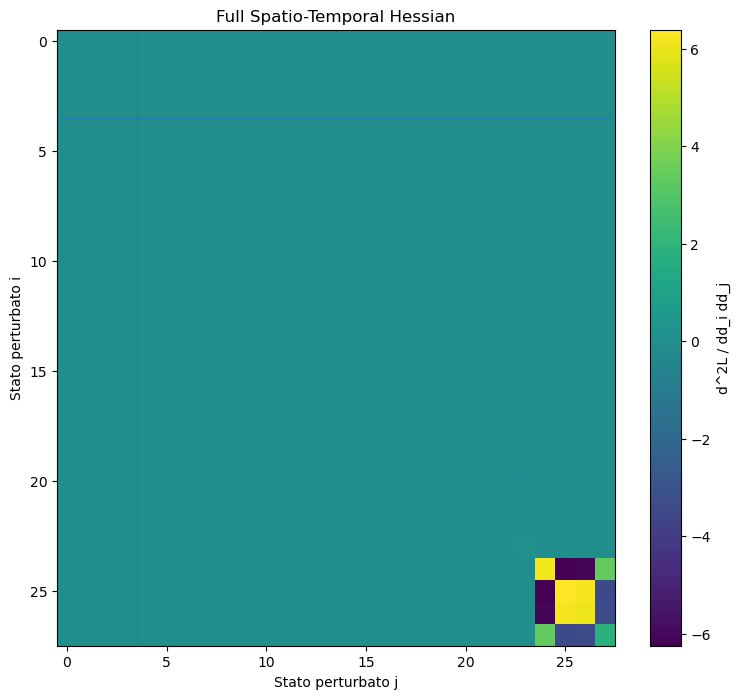

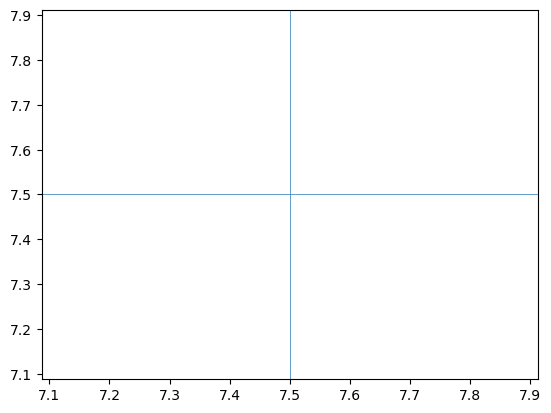

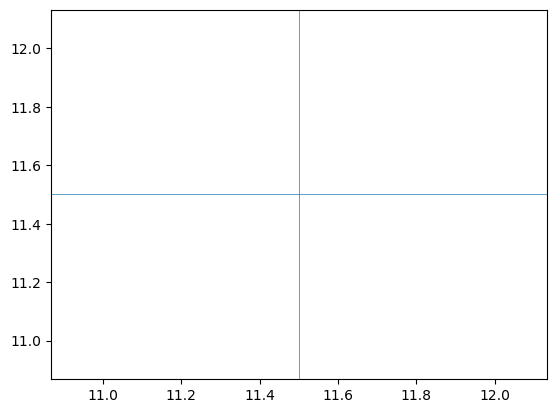

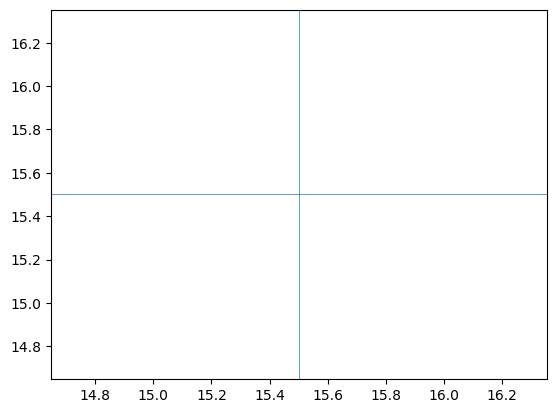

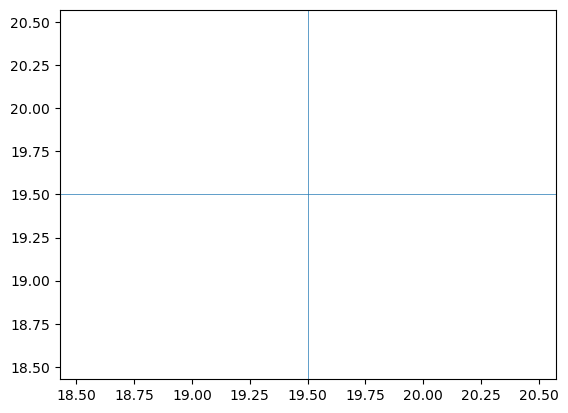

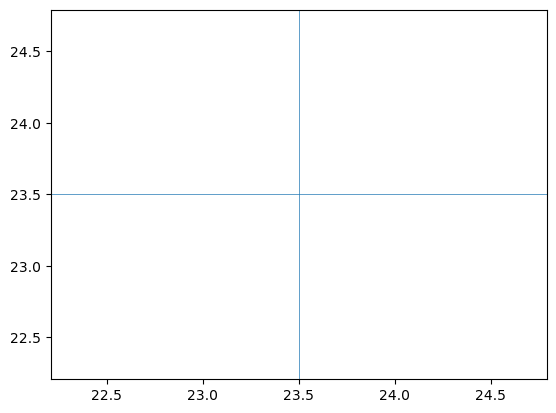

In [10]:
plt.figure(figsize=(9, 8))

plt.imshow(H.detach().numpy(), aspect="auto")

plt.xlabel("Stato perturbato j")
plt.ylabel("Stato perturbato i")
plt.title("Full Spatio-Temporal Hessian")

plt.colorbar(label="d^2L / dd_i dd_j")

for k in range(1, len(x)):
    plt.axhline(k * hidden_size - 0.5, linewidth=0.5)
    plt.axvline(k * hidden_size - 0.5, linewidth=0.5)

    plt.show()

In [11]:
# Leggibilità: norma Frobenius
H_blocks = H.reshape(len(x), hidden_size, len(x), hidden_size)
interaction = torch.zeros(len(x), len(x))

for t in range(len(x)):
    for s in range(len(x)):
        block = H_blocks[t, :, s, :]

        interaction[t, s] = torch.linalg.norm(block)

print(interaction)

tensor([[5.1257e-08, 6.3319e-08, 2.4146e-07, 2.4417e-07, 2.7655e-07, 2.4140e-07,
         1.0738e-07],
        [6.3319e-08, 3.9069e-08, 1.4899e-07, 1.5066e-07, 1.7063e-07, 1.4895e-07,
         6.6257e-08],
        [2.4146e-07, 1.4899e-07, 1.4227e-07, 1.4387e-07, 1.6295e-07, 1.4224e-07,
         6.3272e-08],
        [2.4417e-07, 1.5066e-07, 1.4387e-07, 5.4717e-04, 6.1973e-04, 5.4096e-04,
         2.4064e-04],
        [2.7655e-07, 1.7063e-07, 1.6295e-07, 6.1973e-04, 5.2214e-02, 4.5587e-02,
         2.0279e-02],
        [2.4140e-07, 1.4895e-07, 1.4224e-07, 5.4096e-04, 4.5587e-02, 2.5665e-01,
         1.1417e-01],
        [1.0738e-07, 6.6257e-08, 6.3272e-08, 2.4064e-04, 2.0279e-02, 1.1417e-01,
         2.0380e+01]])


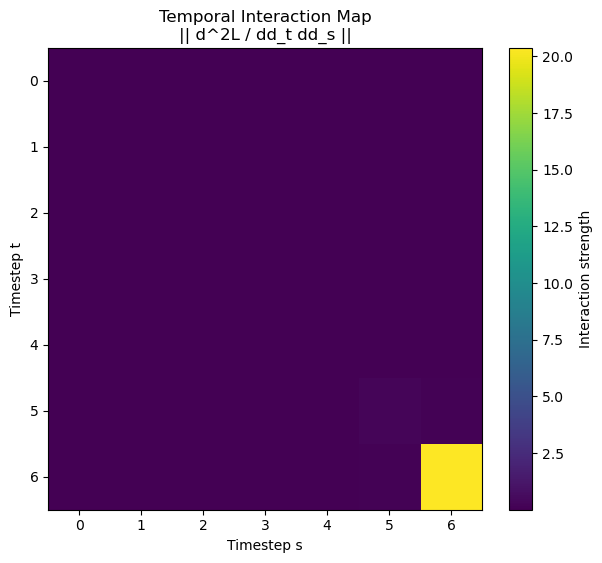

In [12]:
# Nuova heatmap
plt.figure(figsize=(7, 6))

plt.imshow(interaction.detach().numpy(), aspect="auto")

plt.xlabel("Timestep s")
plt.ylabel("Timestep t")
plt.title("Temporal Interaction Map\n" "|| d^2L / dd_t dd_s ||")

plt.colorbar(label="Interaction strength")

plt.xticks(range(7))
plt.yticks(range(7))

plt.show()

In [13]:
# Controllo
symmetry_error = (H - H.T).abs().max()

print("Errore massimo di simmetria:", symmetry_error.item())

Errore massimo di simmetria: 7.450580596923828e-09
